# Análisis y Predicción del Turismo en Costa Rica

**Proyecto Final - BD-143 Programación II**

Colegio Universitario de Cartago | II Cuatrimestre 2026

Integrantes:

- Jeremy Ramírez Pérez

- Gabriel Solano Molina

- Derek Barrantes Torres


Este notebook recorre los principales hallazgos del proyecto: de dónde vienen los datos, qué muestra el análisis exploratorio, cómo se comparó el modelo de predicción, y qué revela el mapa mundial de turistas. Todo el código pesado (extracción de PDFs, conexión a la base de datos, clases de EDA/modelo/mapas) vive organizado en `src/`; aquí solo se reutiliza para presentar los resultados.

## 1. Preparación

Cargamos el CSV ya procesado y las clases del proyecto.

In [43]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), "..", "src"))

import pandas as pd
from IPython.display import Image, display

from eda.procesador_eda import ProcesadorEDA
from visualizacion.visualizador import Visualizador
from visualizacion.mapas import Mapas
from api.cliente_api import ClienteAPI
from helpers.utilidades import Utilidades

RUTA_CSV = os.path.join("..", "data", "processed", "turismo.csv")
RUTA_MODELO = os.path.join("..", "modelos_guardados", "modelo_ml_entrenado.pkl")

# Visualizador guarda cada gráfico como PNG en esta carpeta (relativa a
# donde se ejecute el código); esta función lo muestra justo después.
def mostrar_grafico(nombre_archivo):
    ruta = os.path.join("reports", "figures", nombre_archivo)
    display(Image(filename=ruta))

In [44]:
df_turismo = pd.read_csv(RUTA_CSV)
print(f"{len(df_turismo)} filas | {df_turismo['pais'].nunique()} países | años {df_turismo['anio'].min()}-{df_turismo['anio'].max()}")
df_turismo.head()

6006 filas | 72 países | años 2019-2025


,pais,anio,mes_numero,mes_nombre,turistas
0,alemania,2019,1,enero,8171
1,alemania,2019,2,febrero,9503
2,alemania,2019,3,marzo,9968
3,alemania,2019,4,abril,7304
4,alemania,2019,5,mayo,3957


## 2. Fuente de los datos

Los datos de turismo provienen de los **Informes Semestrales del ICT** (2019-2025), descargados en PDF desde el sitio oficial. Como el ICT no publica un CSV/Excel con el desglose por país y mes para varios años, se construyó un extractor con `pdfplumber` (clase `GestorDatos`) que lee el "Cuadro 1" de cada informe.

Los totales anuales extraídos se validaron contra el Anuario Estadístico de Turismo oficial del ICT, y coincidieron exactamente en todos los casos probados.

El clima proviene de la **API histórica de Open-Meteo**, consultada por la clase `ClienteAPI`.

In [45]:
cliente_api = ClienteAPI()
df_clima = cliente_api.obtener_clima_mensual(
    fecha_inicio=f"{df_turismo['anio'].min()}-01-01",
    fecha_fin=f"{df_turismo['anio'].max()}-12-31"
)
df_clima.head()

,anio,mes_numero,temp_promedio
0,2019,1,19.50
1,2019,2,20.30
2,2019,3,20.61
3,2019,4,21.34
4,2019,5,19.98


## 3. Análisis exploratorio (EDA)

Usamos la clase `ProcesadorEDA` para resumir el dataset y detectar patrones.

In [46]:
eda = ProcesadorEDA(df_turismo, df_clima)
resumen = eda.resumen_general()
resumen

{'filas': 6006,
 'paises': 72,
 'anio_min': 2019,
 'anio_max': 2025,
 'turistas_totales': 16261297,
 'promedio_mensual_por_pais': np.float64(2707.51)}

**Hallazgo:** el dataset acumula más de 16 millones de turistas registrados entre 2019 y 2025, con un promedio mensual por país de alrededor de 2,700 turistas.

In [47]:
correlacion = eda.correlacion_turismo_clima()
print(f"Correlación turismo-clima: {correlacion}")

Correlación turismo-clima: 0.339


La correlación es débil-moderada (~0.34), lo que sugiere que el clima influye, pero no es el factor dominante del turismo — hay otras variables (temporadas vacacionales, feriados, eventos) que probablemente pesan más.

### Estacionalidad y tendencia

Gráfico guardado en reports/figures\turistas_por_mes.png


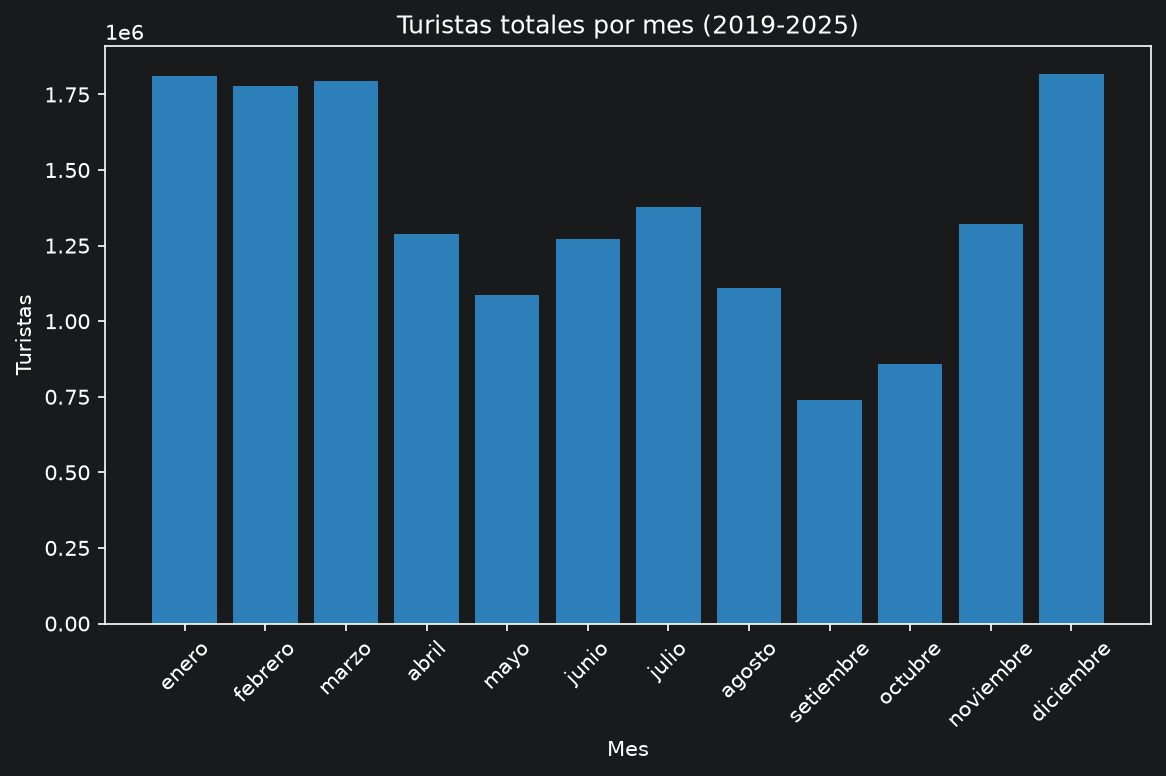

In [48]:
visualizador = Visualizador()

df_mensual = eda.turistas_por_mes()
visualizador.grafico_turistas_por_mes(df_mensual)
mostrar_grafico("turistas_por_mes.png")

Gráfico guardado en reports/figures\tendencia_anual.png


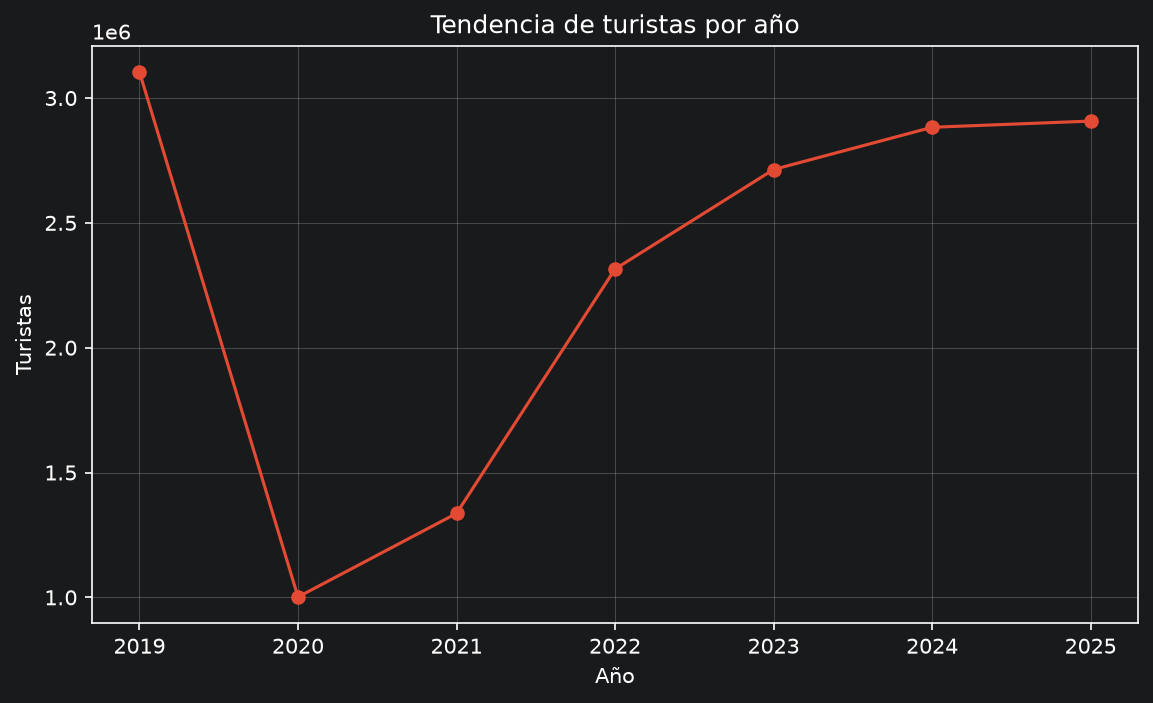

In [49]:
df_anual = eda.turistas_por_anio()
visualizador.grafico_tendencia_anual(df_anual)
mostrar_grafico("tendencia_anual.png")

**Hallazgo:** se observa una caída drástica en 2020-2021 por la pandemia de COVID-19, con recuperación gradual en los años siguientes — parte real de la serie histórica, no un error de datos.

### Países de origen

Gráfico guardado en reports/figures\top_paises.png


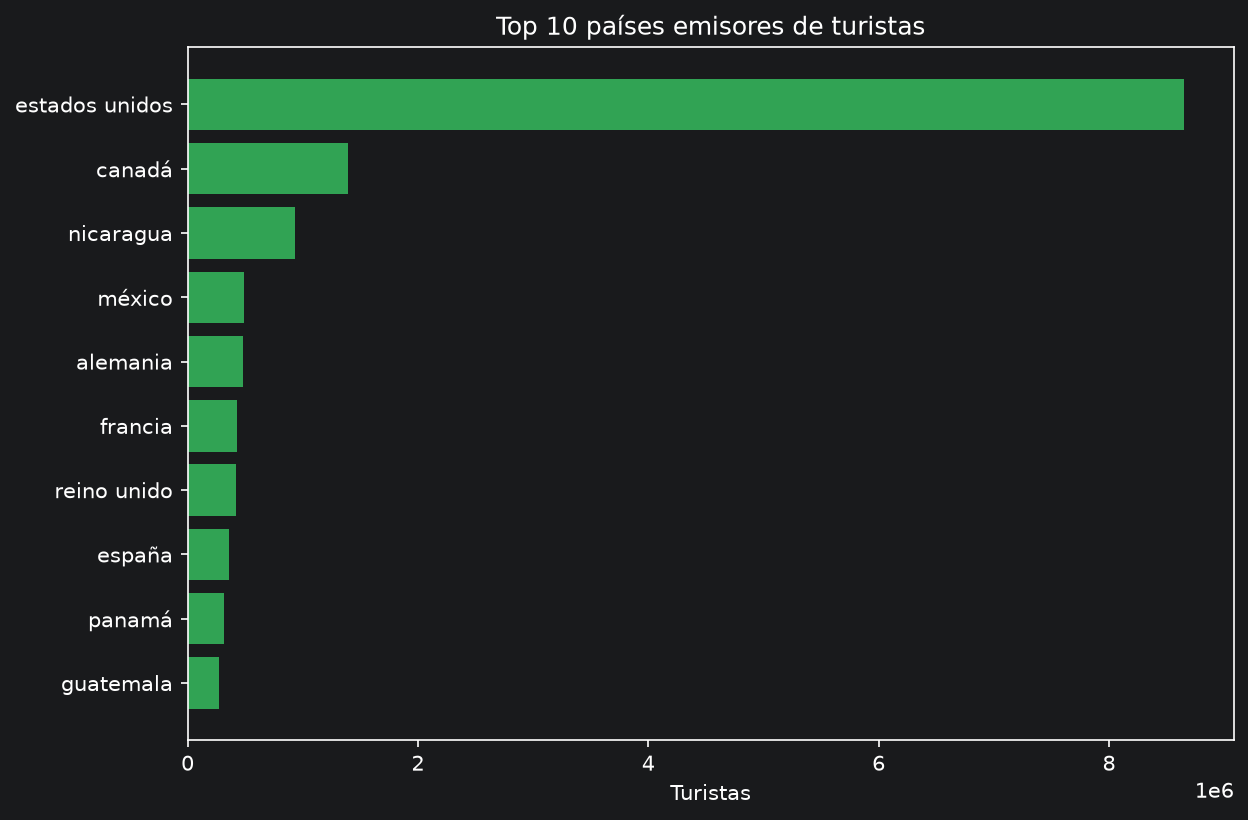

,pais,turistas
23,estados unidos,8651343
11,canadá,1394197
42,nicaragua,932482
41,méxico,493698
0,alemania,485384
26,francia,432382
57,reino unido,421447
22,españa,361082
51,panamá,313410
27,guatemala,269532


In [50]:
df_top = eda.top_paises(n=10)
visualizador.grafico_top_paises(df_top)
mostrar_grafico("top_paises.png")
df_top

**Hallazgo:** Estados Unidos domina ampliamente como país de origen, seguido de un grupo de países centroamericanos y europeos.

### Clima vs. turismo

Gráfico guardado en reports/figures\dispersion_clima.png


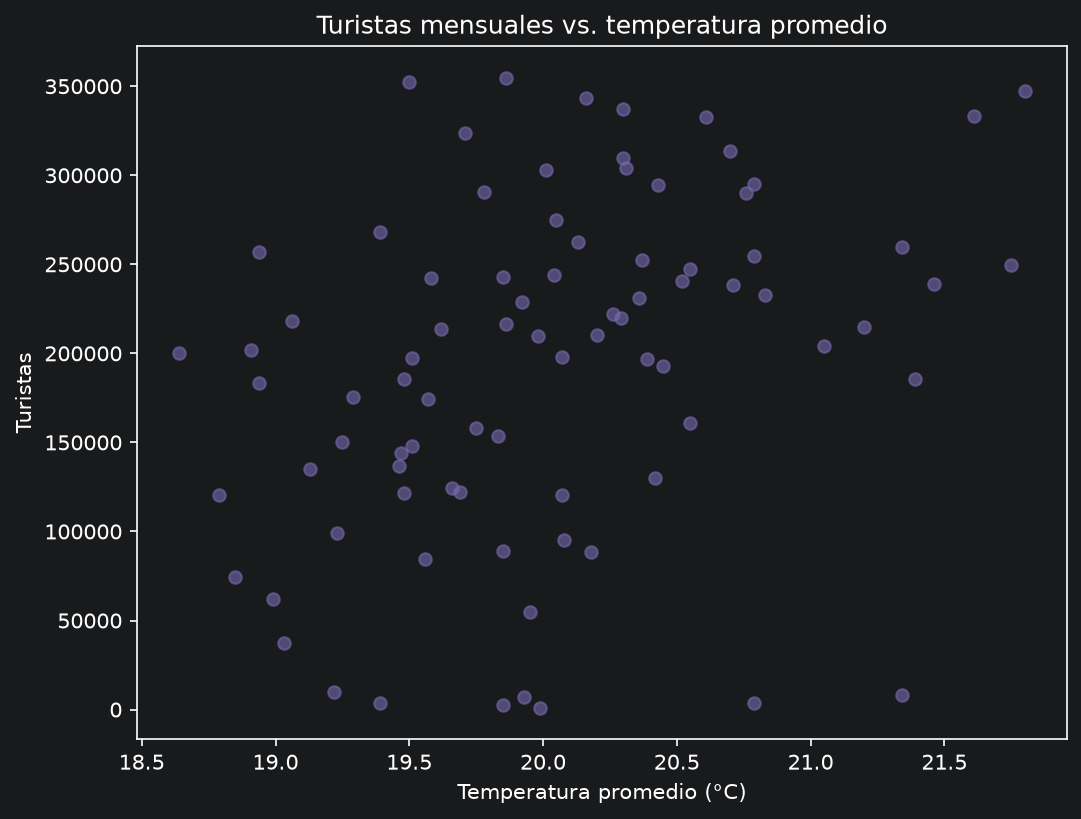

In [51]:
df_combinado = eda.combinar_con_clima()
visualizador.grafico_dispersion_clima(df_combinado)
mostrar_grafico("dispersion_clima.png")

Gráfico guardado en reports/figures\heatmap_mes_anio.png


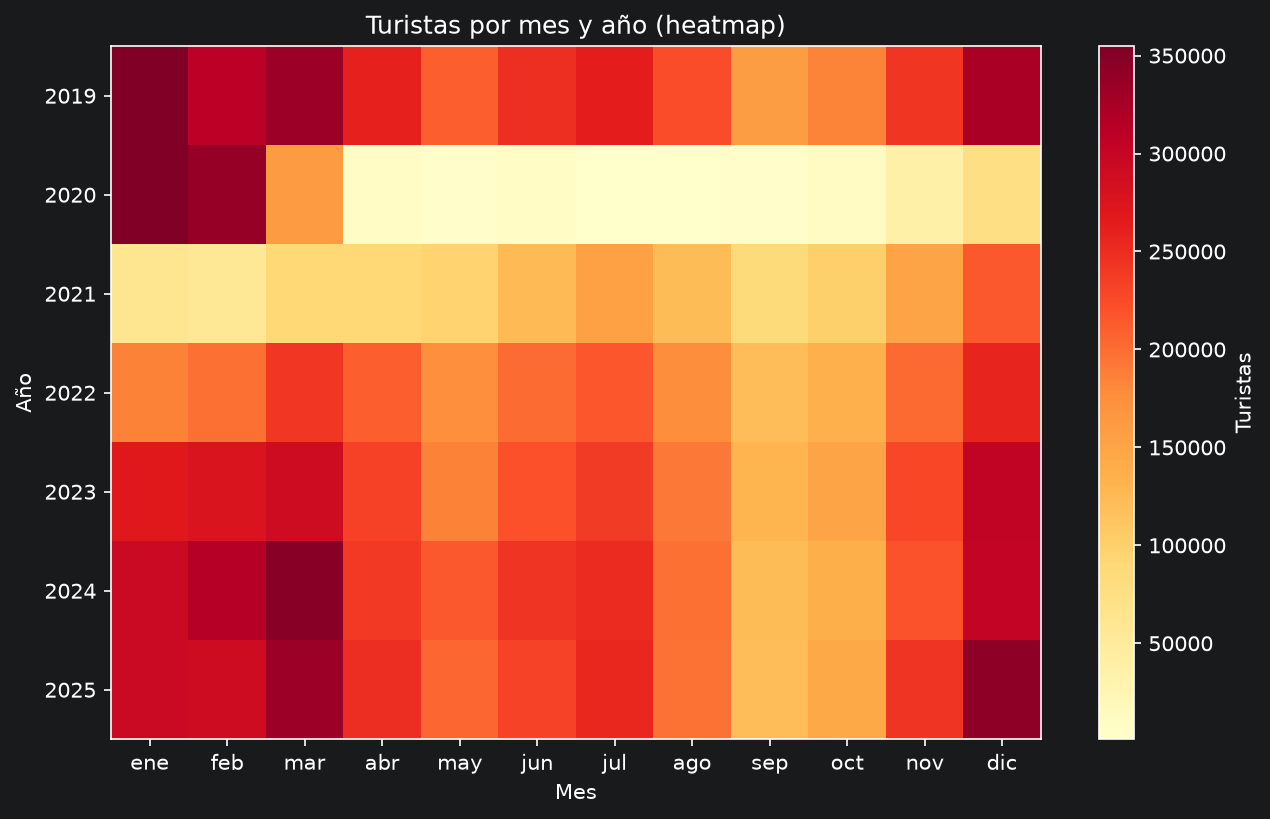

In [52]:
df_pivote = eda.pivote_mes_anio()
visualizador.grafico_heatmap_mes_anio(df_pivote)
mostrar_grafico("heatmap_mes_anio.png")

### Distribución y valores atípicos

Gráfico guardado en reports/figures\boxplot_turistas.png


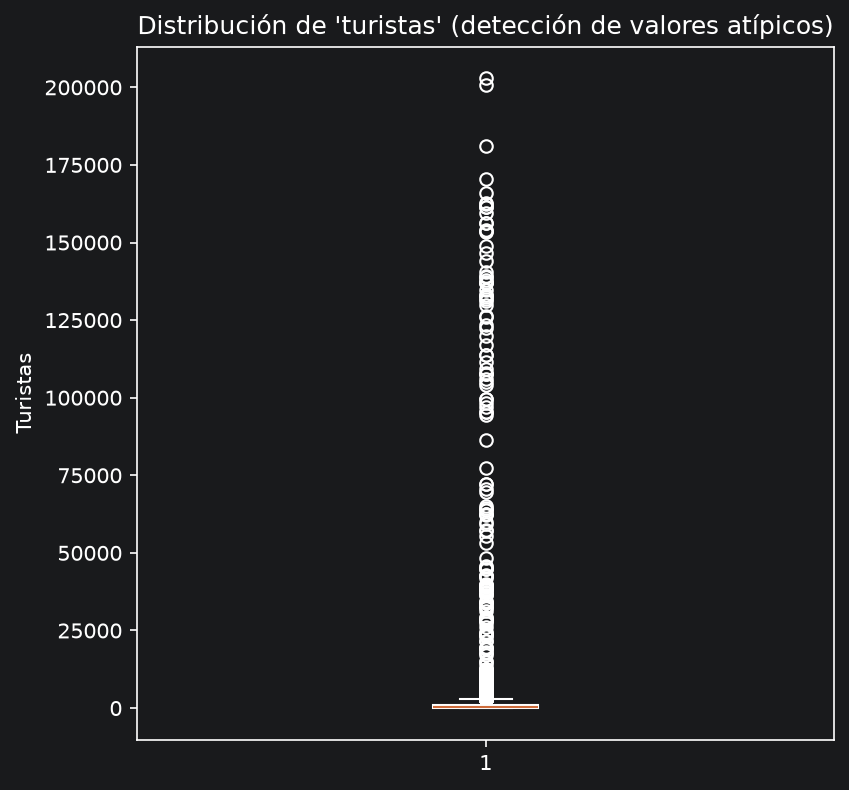

In [53]:
visualizador.grafico_boxplot_turistas(df_turismo)
mostrar_grafico("boxplot_turistas.png")

**Nota:** los valores atípicos que se ven a la derecha del boxplot no son errores — corresponden principalmente a Estados Unidos, que por su volumen se comporta como un caso estructuralmente distinto al resto de los 72 países.

## 4. Modelo de Machine Learning

Se entrenó y comparó un modelo de regresión (KNN, Regresión Lineal, Random Forest) para predecir la cantidad de turistas según país, mes y temperatura promedio. El modelo ya entrenado se carga desde disco (generado por `main.py`).

In [54]:
if os.path.exists(RUTA_MODELO):
    modelo_ml = Utilidades.cargar_objeto(RUTA_MODELO)
    print(f"Mejor modelo: {modelo_ml.mejor_modelo_nombre}")
    if hasattr(modelo_ml, "resultados_benchmarking"):
        display(modelo_ml.resultados_benchmarking)
else:
    print("No se encontró un modelo entrenado. Corre 'python src/main.py' primero.")

Mejor modelo: KNN


,modelo,MAE,RMSE,R2,mejores_parametros
1,KNN,1105.56,36107977.67,0.6503,"{'modelo__n_neighbors': 15, 'modelo__weights':..."
0,Regresión Lineal,1123.72,39203925.67,0.6203,N/A
2,Random Forest,1164.92,44475708.40,0.5693,"{'modelo__max_depth': None, 'modelo__min_sampl..."


**Resultados obtenidos:**

| Modelo | MAE | RMSE | R² |
|---|---|---|---|
| **KNN** (mejor modelo) | 1,105.56 | 36,107,977.67 | 0.6503 |
| Regresión Lineal | 1,123.72 | 39,203,925.67 | 0.6203 |
| Random Forest | 1,164.92 | 44,475,708.40 | 0.5693 |

KNN obtuvo el mejor desempeño (R² ≈ 0.65), un resultado razonable considerando que el modelo solo usa mes, país y temperatura como variables — sin incorporar otros factores relevantes como feriados o eventos especiales.

In [55]:
if os.path.exists(RUTA_MODELO):
    prediccion = modelo_ml.predecir("alemania", 1, 21.5)
    print(f"Predicción de ejemplo (Alemania, enero, 21.5°C): {prediccion:,.0f} turistas")

Predicción de ejemplo (Alemania, enero, 21.5°C): 9,684 turistas


## 5. Mapa mundial

La clase `Mapas` genera un mapa coroplético interactivo (Folium, sobre tiles reales de OpenStreetMap) donde cada país aparece coloreado según su cantidad histórica de turistas hacia Costa Rica.

In [56]:
mapas = Mapas()
mapa = mapas.generar_mapa_folium(df_turismo)
mapa

Aviso: 5 entradas no se pudieron ubicar en el mapa (no son países individuales, son categorías agregadas de la fuente): ['otros asia y el pacífico', 'otros caribe', 'otros europa', 'otros oriente medio', 'otros áfrica']


De los 72 países/categorías del dataset, 67 se ubican en el mapa. Las 5 restantes ('Otros Caribe', 'Otros Europa', 'Otros Asia y El Pacífico', 'Otros África', 'Otros Oriente Medio') son categorías agregadas que el propio ICT reporta sin desglose por país individual, y por eso no tienen una ubicación geográfica única.

## 6. Conclusiones

- El turismo hacia Costa Rica muestra una fuerte **estacionalidad mensual**, con picos y valles que se repiten año a año.
- La pandemia de COVID-19 (2020-2021) generó una caída drástica y atípica en la serie histórica, con recuperación gradual desde 2022.
- **Estados Unidos** es, por un margen amplio, el principal país emisor de turistas.
- La correlación entre clima y turismo es **débil-moderada**, sugiriendo que otros factores (temporada vacacional, feriados, eventos) influyen más que la temperatura por sí sola.
- El modelo **KNN** ofrece el mejor equilibrio de las tres alternativas probadas para predecir turistas por país, mes y clima, aunque con margen de mejora si se incorporan más variables en el futuro.